<a href="https://colab.research.google.com/github/srinath698/ML-engineering-journey/blob/main/ml_end_to_end_workflow_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**The whole note explains how i initially connected my dataset anod how i preprocessed data , handled missing values , creating ml pipelines and implementing those pipelines using trasformers and at last training a linear regression model and evaluation of the model to visualize the results . the whole workflow explain the context and a blue print to build a model from scartch **

In [15]:
import pandas as pd
import numpy as np


In [16]:
df=pd.read_csv('/content/melb_data.csv')

In [17]:
df.head()

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,...,1.0,1.0,202.0,NaN,NaN,Yarra,-37.7996,144.9984,Northern Metropolitan,4019.0
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,...,1.0,0.0,156.0,79.0,1900.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019.0
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,...,2.0,0.0,134.0,150.0,1900.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019.0
3,Abbotsford,40 Federation La,3,h,850000.0,PI,Biggin,4/03/2017,2.5,3067.0,...,2.0,1.0,94.0,NaN,NaN,Yarra,-37.7969,144.9969,Northern Metropolitan,4019.0
4,Abbotsford,55a Park St,4,h,1600000.0,VB,Nelson,4/06/2016,2.5,3067.0,...,1.0,2.0,120.0,142.0,2014.0,Yarra,-37.8072,144.9941,Northern Metropolitan,4019.0


In [18]:
df.shape

(13580, 21)

In [19]:
df.tail()

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
13575,Wheelers Hill,12 Strada Cr,4,h,1245000.0,S,Barry,26/08/2017,16.7,3150.0,...,2.0,2.0,652.0,NaN,1981.0,NaN,-37.90562,145.16761,South-Eastern Metropolitan,7392.0
13576,Williamstown,77 Merrett Dr,3,h,1031000.0,SP,Williams,26/08/2017,6.8,3016.0,...,2.0,2.0,333.0,133.0,1995.0,NaN,-37.85927,144.87904,Western Metropolitan,6380.0
13577,Williamstown,83 Power St,3,h,1170000.0,S,Raine,26/08/2017,6.8,3016.0,...,2.0,4.0,436.0,NaN,1997.0,NaN,-37.85274,144.88738,Western Metropolitan,6380.0
13578,Williamstown,96 Verdon St,4,h,2500000.0,PI,Sweeney,26/08/2017,6.8,3016.0,...,1.0,5.0,866.0,157.0,1920.0,NaN,-37.85908,144.89299,Western Metropolitan,6380.0
13579,Yarraville,6 Agnes St,4,h,1285000.0,SP,Village,26/08/2017,6.3,3013.0,...,1.0,1.0,362.0,112.0,1920.0,NaN,-37.81188,144.88449,Western Metropolitan,6543.0


In [20]:
df.describe()

,Rooms,Price,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,Lattitude,Longtitude,Propertycount
count,13580.000000,1.358000e+04,13580.000000,13580.000000,13580.000000,13580.000000,13518.000000,13580.000000,7130.000000,8205.000000,13580.000000,13580.000000,13580.000000
mean,2.937997,1.075684e+06,10.137776,3105.301915,2.914728,1.534242,1.610075,558.416127,151.967650,1964.684217,-37.809203,144.995216,7454.417378
std,0.955748,6.393107e+05,5.868725,90.676964,0.965921,0.691712,0.962634,3990.669241,541.014538,37.273762,0.079260,0.103916,4378.581772
min,1.000000,8.500000e+04,0.000000,3000.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1196.000000,-38.182550,144.431810,249.000000
25%,2.000000,6.500000e+05,6.100000,3044.000000,2.000000,1.000000,1.000000,177.000000,93.000000,1940.000000,-37.856822,144.929600,4380.000000
50%,3.000000,9.030000e+05,9.200000,3084.000000,3.000000,1.000000,2.000000,440.000000,126.000000,1970.000000,-37.802355,145.000100,6555.000000
75%,3.000000,1.330000e+06,13.000000,3148.000000,3.000000,2.000000,2.000000,651.000000,174.000000,1999.000000,-37.756400,145.058305,10331.000000
max,10.000000,9.000000e+06,48.100000,3977.000000,20.000000,8.000000,10.000000,433014.000000,44515.000000,2018.000000,-37.408530,145.526350,21650.000000


In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13580 entries, 0 to 13579
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Suburb         13580 non-null  object 
 1   Address        13580 non-null  object 
 2   Rooms          13580 non-null  int64  
 3   Type           13580 non-null  object 
 4   Price          13580 non-null  float64
 5   Method         13580 non-null  object 
 6   SellerG        13580 non-null  object 
 7   Date           13580 non-null  object 
 8   Distance       13580 non-null  float64
 9   Postcode       13580 non-null  float64
 10  Bedroom2       13580 non-null  float64
 11  Bathroom       13580 non-null  float64
 12  Car            13518 non-null  float64
 13  Landsize       13580 non-null  float64
 14  BuildingArea   7130 non-null   float64
 15  YearBuilt      8205 non-null   float64
 16  CouncilArea    12211 non-null  object 
 17  Lattitude      13580 non-null  float64
 18  Longti

In [59]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
from sklearn.metrics import accuracy_score

In [23]:
y=df['Price']
x=df.drop(['Price'],axis=1)

In [24]:
print(len(x),len(y))

13580 13580


In [25]:
print(x.head(2),y.head(2))

       Suburb          Address  Rooms Type Method SellerG       Date  \
0  Abbotsford     85 Turner St      2    h      S  Biggin  3/12/2016   
1  Abbotsford  25 Bloomburg St      2    h      S  Biggin  4/02/2016   

   Distance  Postcode  Bedroom2  Bathroom  Car  Landsize  BuildingArea  \
0       2.5    3067.0       2.0       1.0  1.0     202.0           NaN   
1       2.5    3067.0       2.0       1.0  0.0     156.0          79.0   

   YearBuilt CouncilArea  Lattitude  Longtitude             Regionname  \
0        NaN       Yarra   -37.7996    144.9984  Northern Metropolitan   
1     1900.0       Yarra   -37.8079    144.9934  Northern Metropolitan   

   Propertycount  
0         4019.0  
1         4019.0   0    1480000.0
1    1035000.0
Name: Price, dtype: float64


In [26]:
print(x.shape,y.shape)

(13580, 20) (13580,)


identify and drop the columns or indepndent columns which are in x , which doesnt need in models prediction


In [27]:
x.drop(columns=['Address','Propertycount','Longtitude','Lattitude'],inplace=True)

In [28]:
x.columns

Index(['Suburb', 'Rooms', 'Type', 'Method', 'SellerG', 'Date', 'Distance',
       'Postcode', 'Bedroom2', 'Bathroom', 'Car', 'Landsize', 'BuildingArea',
       'YearBuilt', 'CouncilArea', 'Regionname'],
      dtype='object')

In [29]:
pd.to_datetime(x['Date'], errors = 'coerce',dayfirst=True)

,Date
0,2016-12-03
1,2016-02-04
2,2017-03-04
3,2017-03-04
4,2016-06-04
...,...
13575,2017-08-26
13576,2017-08-26
13577,2017-08-26
13578,2017-08-26


In [30]:
print(x['Date'])

0         3/12/2016
1         4/02/2016
2         4/03/2017
3         4/03/2017
4         4/06/2016
            ...    
13575    26/08/2017
13576    26/08/2017
13577    26/08/2017
13578    26/08/2017
13579    26/08/2017
Name: Date, Length: 13580, dtype: object


In [31]:
x['Date'] = pd.to_datetime(x['Date'], errors='coerce', dayfirst=True)
x['soldyear'] = x['Date'].dt.year

In [32]:
print(x['soldyear'])

0        2016
1        2016
2        2017
3        2017
4        2016
         ... 
13575    2017
13576    2017
13577    2017
13578    2017
13579    2017
Name: soldyear, Length: 13580, dtype: int32


In [33]:
print(x['Date'])

0       2016-12-03
1       2016-02-04
2       2017-03-04
3       2017-03-04
4       2016-06-04
           ...    
13575   2017-08-26
13576   2017-08-26
13577   2017-08-26
13578   2017-08-26
13579   2017-08-26
Name: Date, Length: 13580, dtype: datetime64[ns]


In [34]:
x['soldmonth']=x['Date'].dt.month

In [35]:
print(x['soldmonth'])

0        12
1         2
2         3
3         3
4         6
         ..
13575     8
13576     8
13577     8
13578     8
13579     8
Name: soldmonth, Length: 13580, dtype: int32


In [36]:
x['soldday']=x['Date'].dt.day
print(x['soldday'])

0         3
1         4
2         4
3         4
4         4
         ..
13575    26
13576    26
13577    26
13578    26
13579    26
Name: soldday, Length: 13580, dtype: int32


In [37]:
x.head(2)

,Suburb,Rooms,Type,Method,SellerG,Date,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Regionname,soldyear,soldmonth,soldday
0,Abbotsford,2,h,S,Biggin,2016-12-03,2.5,3067.0,2.0,1.0,1.0,202.0,NaN,NaN,Yarra,Northern Metropolitan,2016,12,3
1,Abbotsford,2,h,S,Biggin,2016-02-04,2.5,3067.0,2.0,1.0,0.0,156.0,79.0,1900.0,Yarra,Northern Metropolitan,2016,2,4


In [38]:
x.drop(columns=['Date'],inplace=True)

In [39]:
num_X = x.select_dtypes(include = "number")
cat_X = x.select_dtypes(exclude = "number")

In [40]:
print("numerical_data",num_X.columns)
print("categorical_data",cat_X.columns)


numerical_data Index(['Rooms', 'Distance', 'Postcode', 'Bedroom2', 'Bathroom', 'Car',
       'Landsize', 'BuildingArea', 'YearBuilt', 'soldyear', 'soldmonth',
       'soldday'],
      dtype='object')
categorical_data Index(['Suburb', 'Type', 'Method', 'SellerG', 'CouncilArea', 'Regionname'], dtype='object')


In [42]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

num_trasformation = Pipeline(steps=[('imputer',SimpleImputer(strategy='median')),
                                    ('scaling',StandardScaler())])
cat_trasformation=Pipeline(steps=[('imputer',SimpleImputer(strategy='most_frequent')),
                                   ('onehot',OneHotEncoder(handle_unknown='ignore'))])
preprocessing_transformer = ColumnTransformer(transformers=[('num',num_trasformation,num_X.columns),
                                              ('cat',cat_trasformation,cat_X.columns),
                                              ],
                                  remainder='drop')
preprocessing_transformer

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaling',
                                                  StandardScaler())]),
                                 Index(['Rooms', 'Distance', 'Postcode', 'Bedroom2', 'Bathroom', 'Car',
       'Landsize', 'BuildingArea', 'YearBuilt', 'soldyear', 'soldmonth',
       'soldday'],
      dtype='object')),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 Index(['Suburb', 'Type', 'Method', 'SellerG', 'CouncilArea', 'Regionname'], dtype='object'))])

In [43]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [44]:
x_train.shape,x_test.shape,y_train.shape,y_test.shape

((10864, 18), (2716, 18), (10864,), (2716,))

In [46]:
x_train_preprocessed = preprocessing_transformer.fit_transform(x_train)
x_test_preprocessed = preprocessing_transformer.transform(x_test)

In [48]:
print(x_train_preprocessed.shape)
print(x_test_preprocessed.shape)
print(x_train)

(10864, 616)
(2716, 616)
               Suburb  Rooms Type Method        SellerG  Distance  Postcode  \
12796  Mount Waverley      4    h      S         Jellis      14.2    3149.0   
9642   Mount Waverley      3    h      S            Ray      14.2    3149.0   
3207         Hawthorn      2    u      S         Jellis       4.6    3122.0   
1698    Carlton North      2    u      S  hockingstuart       3.2    3054.0   
761         Bentleigh      4    h      S       Woodards      13.0    3204.0   
...               ...    ...  ...    ...            ...       ...       ...   
5191        Reservoir      3    h      S         Nelson      11.2    3073.0   
13418   Fitzroy North      2    h      S         Nelson       3.6    3068.0   
5390         Richmond      3    t     PI         Jellis       2.6    3121.0   
860    Bentleigh East      2    h      S         Buxton      13.9    3165.0   
7270   West Footscray      3    h      S         Biggin       8.2    3012.0   

       Bedroom2  Bathroom 

In [52]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()

In [53]:
model.fit(x_train_preprocessed,y_train)

LinearRegression()

In [55]:
y_pred=model.predict(x_test_preprocessed)
y_pred

array([2046709.87840404,  616359.34316528,  935720.49109943, ...,
       2423914.68678995, 1666210.15676388, 1019403.97014719])

In [56]:
comparison=pd.DataFrame({'Actual':y_test,'Predicted':y_pred})
comparison

,Actual,Predicted
1061,2600000.0,2.046710e+06
6482,620000.0,6.163593e+05
8395,1000000.0,9.357205e+05
4659,430000.0,6.161665e+05
7386,392250.0,7.222853e+05
...,...,...
10455,1415000.0,1.116041e+06
3616,6500000.0,3.205685e+06
577,2450000.0,2.423915e+06
12620,1155000.0,1.666210e+06


In [58]:
mae=mean_absolute_error(y_test,y_pred)
mae

230501.7679402847

In [60]:
mse=mean_squared_error(y_test,y_pred)
mse

119878807862.55086

In [61]:
import numpy as np
rmse=np.sqrt(mse)
rmse

np.float64(346235.19154261437)

In [62]:
r2_score=r2_score(y_test,y_pred)
r2_score

0.6982008390687849

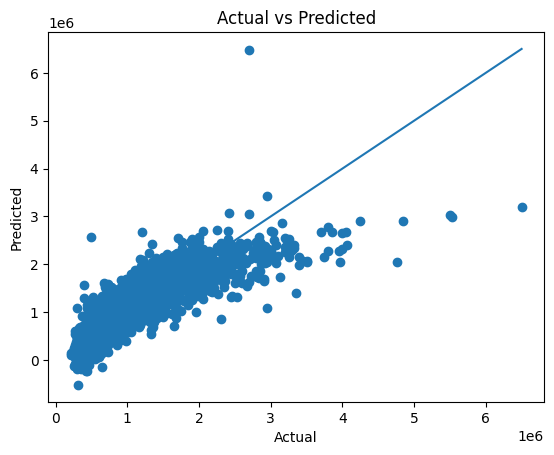

In [67]:
import matplotlib.pyplot as plt
plt.scatter(y_test,y_pred)
plt.plot([y_test.min(),y_test.max()],
         [y_test.min(),y_test.max()]
         )
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Actual vs Predicted')
plt.show()


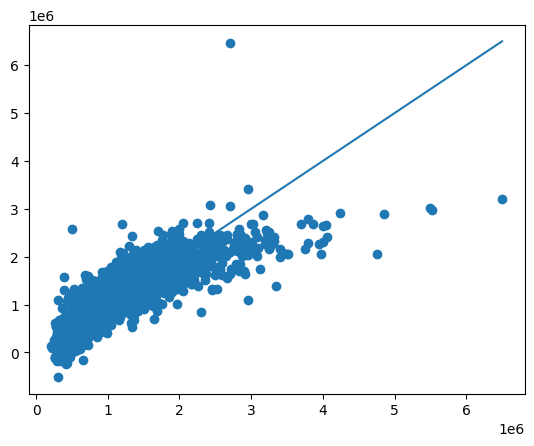

In [68]:
plt.scatter(y_test,y_pred)
plt.plot([y_test.min(),y_test.max()],
         [y_test.min(),y_test.max()]
         )

In [69]:
residuals=y_test-y_pred
residuals

,Price
1061,5.532901e+05
6482,3.640657e+03
8395,6.427951e+04
4659,-1.861665e+05
7386,-3.300353e+05
...,...
10455,2.989590e+05
3616,3.294315e+06
577,2.608531e+04
12620,-5.112102e+05


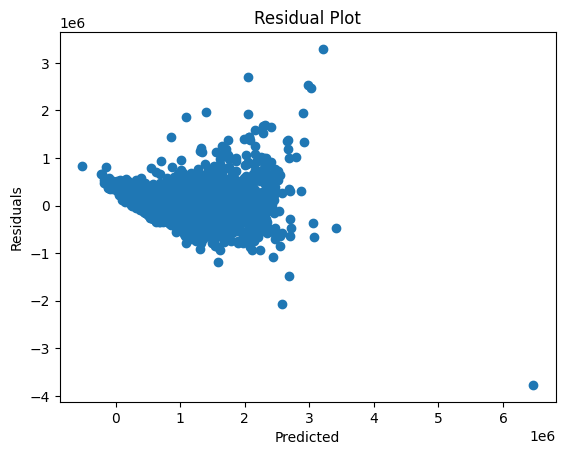

In [70]:
plt.scatter(y_pred,residuals)
plt.xlabel('Predicted')
plt.ylabel('Residuals')
plt.title('Residual Plot')
plt.show()